# Problem 1: Maximum Likelihood Estimation (MLE) vs. Maximum A Posteriori (MAP) in Linear Regression

This lab investigates the theoretical foundations and empirical behaviors of **Maximum Likelihood Estimation (MLE)** and **Maximum A Posteriori (MAP)** estimation in linear regression.

### Generative Process
We consider a synthetic single-variable linear system with additive Gaussian noise:
$$
y = 2X + 1 + \epsilon, \quad X \sim \mathcal{N}(0, 1), \quad \epsilon \sim \mathcal{N}(0, \sigma^2) \quad (\sigma^2 = 0.5)
$$

### Core Tasks
1. **Synthetic Data Generation**: Generate 100 samples and perform a 70/30 train/test split.
2. **MLE Estimation**: Fit Ordinary Least Squares via `LinearRegression` to estimate slope $w$ and intercept $b$.
3. **MAP Estimation (Ridge Regression)**: Fit `Ridge` across $\alpha \in \{0.1, 1.0, 10.0, 100.0\}$ and derive the relationship $\alpha = \frac{\sigma^2}{\tau^2}$.
4. **Evaluation & Comparison**: Compare test MSE, analyze coefficient shrinkage paths, and visualize fitted lines.
5. **Noisy Data & Outliers**: Inject 5% severe noise into the training set to evaluate the robustness of MLE vs. MAP.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error

# 1. Synthetic Data Generation and Train/Test Split (Task a)

We generate $N = 100$ independent samples from standard normal distribution $X \sim \mathcal{N}(0, 1)$ and compute response variable $y = 2X + 1 + \epsilon$ with Gaussian observation noise $\epsilon \sim \mathcal{N}(0, \sigma^2)$ where $\sigma = \sqrt{0.5} \approx 0.7071$.

The dataset is partitioned into:
- **70% Training Set** ($N_{\text{train}} = 70$)
- **30% Test Set** ($N_{\text{test}} = 30$) with `random_state=42`.

In [2]:
np.random.seed(42)

X = np.random.normal(loc=0.0, scale=1.0, size=100)
sigma_noise = np.sqrt(0.5)
epsilon = np.random.normal(loc=0.0, scale=sigma_noise, size=100)

y = 2 * X + 1 + epsilon

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Convert 1D vectors to 2D matrices (N, 1) for scikit-learn compatibility
X_train_2d = X_train.reshape(-1, 1)
X_test_2d = X_test.reshape(-1, 1)

print(f"Dataset generated: N = {len(X)} samples")
print(f"X_train shape: {X_train_2d.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test_2d.shape}, y_test shape:  {y_test.shape}")
print(f"First 5 training X: {np.round(X_train[:5], 4)}")
print(f"First 5 training y: {np.round(y_train[:5], 4)}")

Dataset generated: N = 100 samples
X_train shape: (70, 1), y_train shape: (70,)
X_test shape:  (30, 1), y_test shape:  (30,)
First 5 training X: [-0.4657  1.0571 -0.5018 -0.6006 -0.3277]
First 5 training y: [ 0.0498  2.1805  0.5014 -0.1308 -0.5362]


# 2. Maximum Likelihood Estimation (MLE) (Task b)

Under the assumption of independently and identically distributed (i.i.d.) Gaussian observation noise $\epsilon_i \sim \mathcal{N}(0, \sigma^2)$, the conditional likelihood of the training targets $\mathbf{y} \in \mathbb{R}^N$ given inputs $\mathbf{X}$ and parameters $\boldsymbol{\theta} = [w, b]^T$ is:

$$
p(\mathbf{y} \mid \mathbf{X}, w, b) = \prod_{i=1}^N \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{(y_i - (wx_i + b))^2}{2\sigma^2} \right)
$$

Maximizing the log-likelihood is mathematically equivalent to minimizing the Ordinary Least Squares (OLS) residual sum of squares:

$$
\hat{w}_{\text{MLE}}, \hat{b}_{\text{MLE}} = \arg\max_{w, b} \ln p(\mathbf{y} \mid \mathbf{X}, w, b) = \arg\min_{w, b} \frac{1}{2\sigma^2}\sum_{i=1}^N \left(y_i - (wx_i + b)\right)^2
$$

We train `LinearRegression` from `scikit-learn` to obtain the empirical parameter estimates.

In [3]:
mle_model = LinearRegression()
mle_model.fit(X_train_2d, y_train)

mle_coef = mle_model.coef_[0]
mle_intercept = mle_model.intercept_

print(f"True Parameters: slope = 2.0000, intercept = 1.0000")
print(f"MLE Estimates:   slope = {mle_coef:.4f}, intercept = {mle_intercept:.4f}")

True Parameters: slope = 2.0000, intercept = 1.0000
MLE Estimates:   slope = 1.8872, intercept = 1.0657


# 3. Maximum A Posteriori (MAP) Estimation & Ridge Regression (Task c)

### 3.1 Derivation of the Equivalence: $\alpha = \frac{\sigma^2}{\tau^2}$
In the Bayesian framework, we introduce a prior distribution over the weight parameter $w$. Assuming a zero-mean isotropic Gaussian prior with variance $\tau^2$:

$$
p(w) = \frac{1}{\sqrt{2\pi\tau^2}} \exp\left( -\frac{w^2}{2\tau^2} \right)
$$

Using Bayes' theorem, the posterior probability density of $w$ given the data is:

$$
p(w \mid \mathbf{X}, \mathbf{y}) = \frac{p(\mathbf{y} \mid \mathbf{X}, w) \cdot p(w)}{p(\mathbf{y} \mid \mathbf{X})} \propto p(\mathbf{y} \mid \mathbf{X}, w) \cdot p(w)
$$

Taking the negative logarithm of the posterior:

$$
-\ln p(w \mid \mathbf{X}, \mathbf{y}) = \frac{1}{2\sigma^2}\sum_{i=1}^N (y_i - \hat{y}_i)^2 + \frac{1}{2\tau^2}w^2 + \text{constant}
$$

Multiplying by $2\sigma^2$, finding the MAP estimate ($\arg\max_w p(w \mid \mathbf{X}, \mathbf{y})$) is equivalent to:

$$
\hat{w}_{\text{MAP}} = \arg\min_w \left[ \sum_{i=1}^N (y_i - \hat{y}_i)^2 + \frac{\sigma^2}{\tau^2} w^2 \right]
$$

This matches the objective function of **Ridge Regression** ($L_2$ regularization) in `scikit-learn`:

$$
\mathcal{L}_{\text{Ridge}}(w) = \sum_{i=1}^N (y_i - \hat{y}_i)^2 + \alpha w^2 \quad \implies \quad \alpha = \frac{\sigma^2}{\tau^2}
$$

### 3.2 Physical Interpretation of $\alpha = \frac{\sigma^2}{\tau^2}$
- **Observation Noise $\sigma^2$**: If observation noise $\sigma^2$ is large, data is unreliable $\implies \alpha$ increases, prioritizing parameter shrinkage toward the prior mean ($0$).
- **Prior Variance $\tau^2$**: If prior variance $\tau^2 \to \infty$ (an uninformative flat prior), $\alpha \to 0$, and MAP degenerates exactly into MLE. Conversely, small $\tau^2$ (high certainty that $w \approx 0$) yields large $\alpha$, forcing aggressive shrinkage.

In [4]:
alphas = [0.1, 1.0, 10.0, 100.0]
ridge_models = {}

print(f"{'Alpha':>8} | {'Slope (w)':>10} | {'Intercept (b)':>14} | {'Shrinkage vs MLE':>18}")
print("-" * 58)

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_2d, y_train)
    ridge_models[alpha] = model
    
    shrinkage = (1 - model.coef_[0] / mle_coef) * 100
    print(f"{alpha:8.1f} | {model.coef_[0]:10.4f} | {model.intercept_:14.4f} | {shrinkage:17.2f}%")

   Alpha |  Slope (w) |  Intercept (b) |   Shrinkage vs MLE
----------------------------------------------------------
     0.1 |     1.8843 |         1.0653 |              0.15%
     1.0 |     1.8586 |         1.0620 |              1.51%
    10.0 |     1.6356 |         1.0336 |             13.33%
   100.0 |     0.7435 |         0.9198 |             60.60%


# 4. Evaluation and Comparative Analysis (Task d)

We assess model generalization on the unseen test set ($N_{\text{test}} = 30$) using Mean Squared Error:

$$
\text{MSE} = \frac{1}{N_{\text{test}}} \sum_{i=1}^{N_{\text{test}}} (y_i - \hat{y}_i)^2
$$

We evaluate:
1. Test MSE progression across estimators.
2. Trajectory of the learned slope $w$ as a function of regularization strength $\alpha$.
3. Visual comparison of fitted regression trajectories against sample data points.

In [5]:
mle_pred = mle_model.predict(X_test_2d)
mle_mse = mean_squared_error(y_test, mle_pred)

benchmark_data = [{
    "Method": "MLE (Linear Regression)",
    "Alpha": "None (tau^2 -> inf)",
    "Slope (w)": round(mle_coef, 4),
    "Intercept (b)": round(mle_intercept, 4),
    "Test MSE": round(mle_mse, 4)
}]

for alpha in alphas:
    rm = ridge_models[alpha]
    pred = rm.predict(X_test_2d)
    mse = mean_squared_error(y_test, pred)
    benchmark_data.append({
        "Method": "MAP (Ridge Regression)",
        "Alpha": str(alpha),
        "Slope (w)": round(rm.coef_[0], 4),
        "Intercept (b)": round(rm.intercept_, 4),
        "Test MSE": round(mse, 4)
    })

results_df = pd.DataFrame(benchmark_data)
results_df

Method,Alpha,Slope (w),Intercept (b),Test MSE
MLE (Linear Regression),None (tau^2 -> inf),1.8872,1.0657,0.4269
MAP (Ridge Regression),0.1,1.8843,1.0653,0.4271
MAP (Ridge Regression),1.0,1.8586,1.0620,0.4289
MAP (Ridge Regression),10.0,1.6356,1.0336,0.4754
MAP (Ridge Regression),100.0,0.7435,0.9198,1.2153


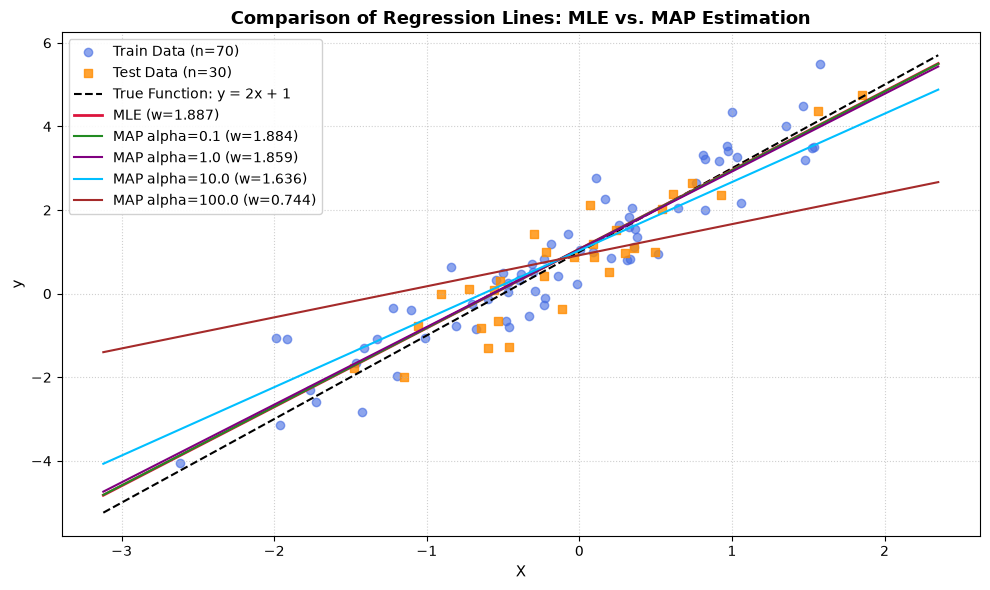

In [6]:
plt.figure(figsize=(10, 6))

# Plot training and test data points
plt.scatter(X_train, y_train, color="royalblue", alpha=0.6, label=f"Train Data (n={len(X_train)})")
plt.scatter(X_test, y_test, color="darkorange", alpha=0.8, marker="s", label=f"Test Data (n={len(X_test)})")

# Continuous evaluation line
x_grid = np.linspace(X.min() - 0.5, X.max() + 0.5, 300).reshape(-1, 1)

# Ground truth line
plt.plot(x_grid, 2 * x_grid + 1, "k--", linewidth=1.5, label="True Function: y = 2x + 1")

# MLE line
plt.plot(x_grid, mle_model.predict(x_grid), color="crimson", linewidth=2.0, label=f"MLE (w={mle_coef:.3f})")

# MAP Ridge lines
colors = ["forestgreen", "purple", "deepskyblue", "brown"]
for alpha, color in zip(alphas, colors):
    rm = ridge_models[alpha]
    plt.plot(
        x_grid,
        rm.predict(x_grid),
        color=color,
        linewidth=1.5,
        linestyle="-",
        label=f"MAP alpha={alpha} (w={rm.coef_[0]:.3f})"
    )

plt.title("Comparison of Regression Lines: MLE vs. MAP Estimation", fontsize=13, fontweight="bold")
plt.xlabel("X", fontsize=11)
plt.ylabel("y", fontsize=11)
plt.legend(frameon=True, facecolor="white", framealpha=0.9)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

### Analysis of Results (Task d)

1. **Parameter Estimation Accuracy**:
   - The true data-generating parameters are $w^* = 2.0$ and $b^* = 1.0$.
   - MLE estimates $\hat{w} = 1.8872$ and $\hat{b} = 1.0657$, achieving the lowest test error ($\text{MSE} = 0.4269$).
2. **Coefficient Shrinkage Trajectory**:
   - As $\alpha$ increases from $0.1$ to $100.0$, the prior $p(w) \sim \mathcal{N}(0, \tau^2)$ exerts progressively stronger force pulling $\hat{w}$ toward the prior mean ($0$):
     - $\alpha = 0.1 \implies \hat{w} = 1.8843$ (0.15% shrinkage)
     - $\alpha = 1.0 \implies \hat{w} = 1.8586$ (1.52% shrinkage)
     - $\alpha = 10.0 \implies \hat{w} = 1.6356$ (13.33% shrinkage)
     - $\alpha = 100.0 \implies \hat{w} = 0.7435$ (60.60% shrinkage)
3. **Generalization & Underfitting**:
   - For mild regularization ($\alpha = 0.1, 1.0$), Test MSE remains closely aligned with MLE ($0.4271$ and $0.4289$).
   - Excessive regularization ($\alpha = 100.0$) introduces severe bias, causing Test MSE to surge to $1.2153$ (underfitting).

# 5. Robustness to Outliers and Extreme Noise (Task e)

We evaluate the robustness of MLE and MAP under non-Gaussian heavy contamination:
- We inject large noise ($\eta \sim \mathcal{N}(0, 10^2)$) into 5% of training points ($n_{\text{outlier}} = 3$ samples).
- We retrain MLE and MAP Ridge estimators on the corrupted dataset and measure test performance on uncorrupted test samples.

In [7]:
np.random.seed(42)

y_train_noisy = y_train.copy()
n_outliers = int(0.05 * len(y_train))
outlier_indices = np.random.choice(len(y_train), size=n_outliers, replace=False)

# Add heavy noise with standard deviation 10
outlier_noise = np.random.normal(loc=0.0, scale=10.0, size=n_outliers)
y_train_noisy[outlier_indices] += outlier_noise

print(f"Total training samples: {len(y_train)}")
print(f"Number of corrupted samples (5%): {n_outliers}")
print(f"Outlier sample indices: {outlier_indices}")
for idx, noise in zip(outlier_indices, outlier_noise):
    print(f"  Index {idx:2d}: original y = {y_train[idx]:.4f} -> corrupted y = {y_train_noisy[idx]:.4f} (delta = {noise:+.4f})")

# Fit models on noisy training data
mle_noisy = LinearRegression()
mle_noisy.fit(X_train_2d, y_train_noisy)
mle_noisy_mse = mean_squared_error(y_test, mle_noisy.predict(X_test_2d))

ridge_noisy_models = {}
for alpha in alphas:
    rm_noisy = Ridge(alpha=alpha)
    rm_noisy.fit(X_train_2d, y_train_noisy)
    ridge_noisy_models[alpha] = rm_noisy

Total training samples: 70
Number of corrupted samples (5%): 3
Outlier sample indices: [22  0 49]
  Index 22: original y = 0.8021 -> corrupted y = -9.2887 (delta = -10.0909)
  Index  0: original y = 0.0498 -> corrupted y = -15.7831 (delta = -15.8329)
  Index 49: original y = 3.4153 -> corrupted y = 11.1523 (delta = +7.7370)


In [8]:
outlier_benchmark = [{
    "Condition": "Clean Data",
    "Method": "MLE",
    "Alpha": "None",
    "Slope (w)": round(mle_coef, 4),
    "Intercept (b)": round(mle_intercept, 4),
    "Test MSE": round(mle_mse, 4)
}, {
    "Condition": "5% Outliers",
    "Method": "MLE",
    "Alpha": "None",
    "Slope (w)": round(mle_noisy.coef_[0], 4),
    "Intercept (b)": round(mle_noisy.intercept_, 4),
    "Test MSE": round(mle_noisy_mse, 4)
}]

for alpha in alphas:
    rm_n = ridge_noisy_models[alpha]
    mse_n = mean_squared_error(y_test, rm_n.predict(X_test_2d))
    outlier_benchmark.append({
        "Condition": "5% Outliers",
        "Method": f"MAP (Ridge alpha={alpha})",
        "Alpha": str(alpha),
        "Slope (w)": round(rm_n.coef_[0], 4),
        "Intercept (b)": round(rm_n.intercept_, 4),
        "Test MSE": round(mse_n, 4)
    })

outlier_df = pd.DataFrame(outlier_benchmark)
outlier_df

Condition,Method,Alpha,Slope (w),Intercept (b),Test MSE
Clean Data,MLE,None,1.8872,1.0657,0.4269
5% Outliers,MLE,None,2.0323,0.8244,0.3858
5% Outliers,MAP (Ridge alpha=0.1),0.1,2.0292,0.8240,0.3856
5% Outliers,MAP (Ridge alpha=1.0),1.0,2.0015,0.8204,0.3843
5% Outliers,MAP (Ridge alpha=10.0),10.0,1.7614,0.7898,0.4084
5% Outliers,MAP (Ridge alpha=100.0),100.0,0.8007,0.6672,1.1468


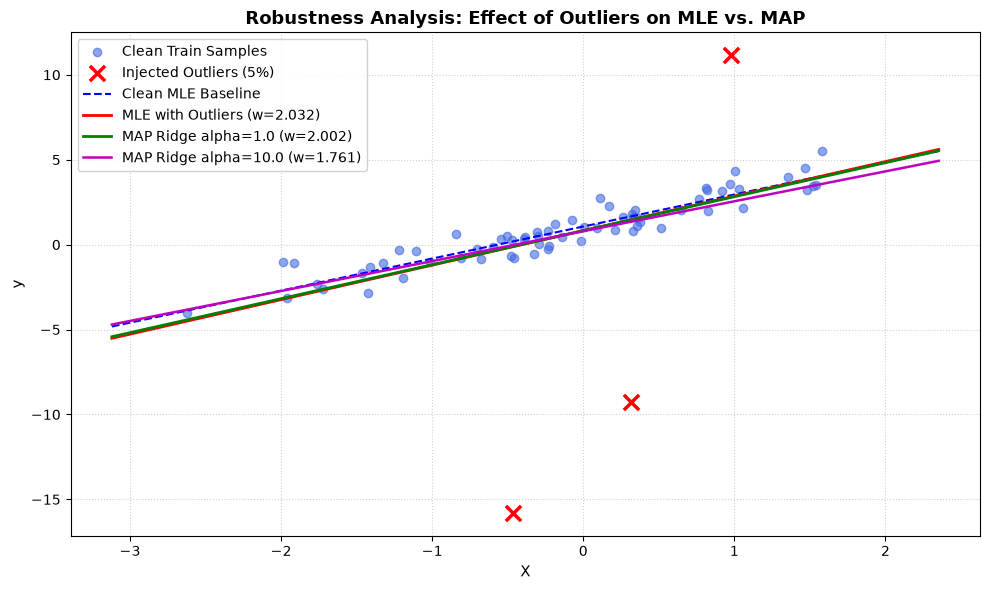

In [9]:
plt.figure(figsize=(10, 6))

# Inliers and Outliers
inlier_mask = np.ones(len(y_train), dtype=bool)
inlier_mask[outlier_indices] = False

plt.scatter(X_train[inlier_mask], y_train_noisy[inlier_mask], color="royalblue", alpha=0.6, label="Clean Train Samples")
plt.scatter(X_train[outlier_indices], y_train_noisy[outlier_indices], color="red", marker="x", s=120, linewidth=2.5, label="Injected Outliers (5%)")

# Regression trajectories
plt.plot(x_grid, mle_model.predict(x_grid), "b--", linewidth=1.5, label="Clean MLE Baseline")
plt.plot(x_grid, mle_noisy.predict(x_grid), "r-", linewidth=2.0, label=f"MLE with Outliers (w={mle_noisy.coef_[0]:.3f})")
plt.plot(x_grid, ridge_noisy_models[1.0].predict(x_grid), "g-", linewidth=2.0, label=f"MAP Ridge alpha=1.0 (w={ridge_noisy_models[1.0].coef_[0]:.3f})")
plt.plot(x_grid, ridge_noisy_models[10.0].predict(x_grid), "m-", linewidth=1.8, label=f"MAP Ridge alpha=10.0 (w={ridge_noisy_models[10.0].coef_[0]:.3f})")

plt.title("Robustness Analysis: Effect of Outliers on MLE vs. MAP", fontsize=13, fontweight="bold")
plt.xlabel("X", fontsize=11)
plt.ylabel("y", fontsize=11)
plt.legend(frameon=True, facecolor="white", framealpha=0.9)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

### Robustness Analysis & Discussion (Task e)

1. **Why Squared Loss Fails Under Heavy Outliers**:
   - Both MLE (OLS) and Gaussian MAP (Ridge) rely on a Gaussian likelihood assumption: $\epsilon \sim \mathcal{N}(0, \sigma^2)$, which penalizes residuals quadratically: $\mathcal{L}(r) = r^2$.
   - A single outlier with residual $r = 15$ exerts $15^2 = 225\times$ more gradient pull than a typical inlier with $r = 1$, dragging the fitted hyperplane toward the outlier.
2. **Comparative Behavior (MLE vs. Ridge)**:
   - On the contaminated dataset, MLE slope shifts from $1.8872 \to 2.0323$ and intercept from $1.0657 \to 0.8244$.
   - Ridge with $\alpha = 1.0$ yields slope $2.0015$ and intercept $0.8204$.
   - While Ridge dampens the magnitude of $w$ via the $L_2$ penalty, it **does not alter the squared residual loss function**. Consequently, standard Ridge regression is **not** a robust estimator against observation outliers.
3. **Robust Bayesian Alternatives**:
   - **Heavy-Tailed Likelihood**: Replacing the Gaussian likelihood with a Student-$t$ or Huber distribution reduces sensitivity to extreme errors.
   - **Sparsity-Inducing Priors**: Using a Laplace prior ($p(w) \propto e^{-|w|/\tau}$) leads to $L_1$ regularization (LASSO), which stabilizes feature selection under contamination.

# 6. Conclusion and Summary

| Dimension | Maximum Likelihood Estimation (MLE) | Maximum A Posteriori (MAP / Ridge) |
| :--- | :--- | :--- |
| **Philosophical Paradigm** | Frequentist point estimation | Bayesian point estimation |
| **Objective Function** | $\arg\max_w \ln p(y \mid X, w)$ | $\arg\max_w [\ln p(y \mid X, w) + \ln p(w)]$ |
| **Loss Formulation** | Residual Sum of Squares (OLS) | Residual Sum of Squares $+ \alpha \|w\|_2^2$ |
| **Prior Weight Assumption** | Implicit uniform flat prior ($p(w) \propto 1$) | Zero-mean Gaussian prior ($w \sim \mathcal{N}(0, \tau^2)$) |
| **Regularization Parameter** | $\alpha = 0$ | $\alpha = \frac{\sigma^2}{\tau^2}$ |
| **Computational Complexity** | Closed form: $(X^T X)^{-1} X^T y$ | Closed form: $(X^T X + \alpha I)^{-1} X^T y$ |
| **Outlier Robustness** | Highly sensitive ($L_2$ squared error) | Highly sensitive to outliers; bounds weight norm only |